---
title: "L4-07 · Identification before estimation"
short_title: "Identification before estimation"
subtitle: "If two models that fit the same exact distribution disagree about an intervention, no estimator and no sample size can settle the question; identification depends on assumptions and distributions, estimation on data."
description: "Decide whether a causal quantity is fixed by a graph and an observational distribution, derive its estimand by truncated factorization or do-calculus, and only then estimate it."
tags: [level-4, coursebook]
---

(lesson-l4-07)=

:::{div}
:class: qcai-meta
![Level 4 icon](../../_static/icons/qicon-level-4.svg) **Level 4 · Undergraduate** · about 110 minutes  
**Big idea.** If two models that fit the same exact distribution disagree about an intervention, no estimator and no sample size can settle the question; identification depends on assumptions and distributions, estimation on data.  
**Before this lesson.** [L4-01](#lesson-l4-01), [L4-04](#lesson-l4-04), [L4-05](#lesson-l4-05)  
**Lab.** [Confounding and intervention](../../labs/03-causal-inference.ipynb)
:::

## What you will be able to do

- Build two structural models, compatible with one graph, that share an observational distribution and disagree about $P(y \mid do(x))$, and use the pair to prove that the effect is not identified.
- Derive $P(v \mid do(x))$ in a fully observed Markovian model by the truncated factorization, stating the positivity condition it needs.
- Apply the three rules of do-calculus, checking each rule's separation condition in the correct mutilated graph.
- Split the error of a causal estimate into an estimation part that shrinks with the sample size and an identification part that does not.

## Why this matters

A health system holds ten million records. Among treated patients 80 percent recover; among untreated patients 20 percent do. A manager asks for another ten million records to pin down the effect of treatment. The request sounds reasonable and is useless. This lesson exhibits two models of the clinic that produce exactly the same table of frequencies, to every decimal place, while one says treatment raises recovery by 60 percentage points and the other says it does nothing at all. More records sharpen the table. They cannot choose between the models.

That is why causal inference has two stages with different jobs. **Identification** asks whether the assumptions (a graph, the absence of certain hidden causes, positivity) force a unique answer from the exact distribution, and if so, which formula of that distribution equals the causal quantity. **Estimation** then approximates that formula from finite data, with an uncertainty statement. Skipping the first stage produces confident intervals around the wrong number. The tools in this lesson, the truncated factorization and Pearl's do-calculus, are the machinery of the first stage [@pearlcausality; @pearl].

:::{dropdown} Key terms

**Identifiable**
: A causal quantity is identifiable in a class of models if every two models in the class that produce the same observational distribution give it the same value.

**Estimand**
: A formula that writes the causal quantity as a function of the observational distribution, such as $\sum_z P(y \mid x, z)P(z)$.

**Estimator**
: A rule that turns a finite sample into a number that approximates an estimand, such as plugging in sample frequencies.

**Truncated factorization**
: In a fully observed Markovian model, $P(v \mid do(x))$ is the usual product of $P(v_i \mid pa_i)$ with the factors of the intervened variables deleted.

**Mutilated graph**
: A graph with some arrows deleted: $G_{\overline{X}}$ removes the arrows into $X$, $G_{\underline{X}}$ removes the arrows out of $X$.

**Do-calculus**
: Three rules that rewrite expressions containing $do(\cdot)$, each licensed by a d-separation statement in a mutilated graph.

**Positivity**
: Every conditional probability the formula uses is defined: the conditioning values occur with positive probability.

:::


In [1]:
import sys, pathlib, subprocess
here = pathlib.Path.cwd()
root = next((p for p in [here, *here.parents] if (p / "qcai").is_dir()), None)
if root is None:  # for example on Google Colab: fetch the course's small teaching package
    root = pathlib.Path("quantum-causal-ai")
    if not root.exists():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/pozapas/quantum-causal-ai.git", str(root)], check=True)
    root = root.resolve()
sys.path.insert(0, str(root))
from qcai.viz import show as _show, show_mpl as _show_mpl
from qcai.lessonfigs import l4_07 as _lessonfigs

## Two models that no data can tell apart

Take binary $X$ (treatment) and $Y$ (recovery) with $P(X{=}1) = 0.5$, $P(Y{=}1 \mid X{=}1) = 0.8$ and $P(Y{=}1 \mid X{=}0) = 0.2$. Two structural models produce these numbers.

- **Model A** (treatment works): draw $X$ with $P(X{=}1) = 0.5$, then draw $Y$ from $P(y \mid x)$.
- **Model B** (treatment is inert): draw a hidden $U$ with $P(U{=}1) = 0.5$, draw $X$ with $P(X{=}1 \mid U{=}1) = 0.8$ and $P(X{=}1 \mid U{=}0) = 0.2$, and set $Y = U$.

In model B, $P(X{=}1, Y{=}1) = P(U{=}1)\,P(X{=}1 \mid U{=}1) = 0.5 \cdot 0.8 = 0.4$, the same as $0.5 \cdot 0.8$ in model A. The other three cells match too: $0.4, 0.1, 0.1, 0.4$ for $(x, y) = (0,0), (0,1), (1,0), (1,1)$.

```{mermaid}
graph LR
  U((U hidden)) -.-> X
  U -.-> Y
  X --> Y
```

*Both models fit this graph, with a hidden $U$ (dashed) pointing into $X$ and $Y$. Model A gives the dashed arrows no influence; model B gives the solid arrow $X \to Y$ no influence. A graph allows an arrow to matter; it does not force it to.*

:::{figure} ../../_static/animations/l4_07_two_models.mp4
:alt: Two small causal graphs on the left, model A with X to Y and model B with a hidden U pointing to X and Y. On the right, violet and cyan bars for P(x, y) are identical; after the arrows into X are cut, the bars for P(Y=1 given do(X=x)) differ.
:width: 100%

Observational bars are identical; interventional bars are not. The data fix the left chart and leave the right chart open.
:::

:::{dropdown} What the animation shows
Model A (violet) is the graph $X \to Y$ with $Y \sim P(y \mid x)$. Model B (cyan) has a hidden $U$ pointing to $X$ and to $Y$, with $Y = U$. Each model draws its four bars for $P(x, y)$; the bars coincide at $0.4, 0.1, 0.1, 0.4$ and the label reads that they are identical for every $(x, y)$. Then the intervention $do(X{=}x)$ is performed by graph surgery: the arrow from $U$ into $X$ is cut, and $X$ becomes a square holding the set value $x$. The chart becomes $P(Y{=}1 \mid do(X{=}x))$: model A gives $0.2$ and $0.8$, model B gives $0.5$ and $0.5$. The effects are written as A: $0.8 - 0.2 = 0.6$ and B: $0.5 - 0.5 = 0$, and the closing line reads: same $P(x, y)$, different effects, so more data cannot decide.
:::

$$
P_A(Y{=}1 \mid do(X{=}x)) = P(Y{=}1 \mid X{=}x), \qquad P_B(Y{=}1 \mid do(X{=}x)) = P(Y{=}1) = 0.5
$$ (eq-l4-07-two)

In model A the mechanism for $Y$ is $P(y \mid x)$ itself, so setting $X$ by hand leaves it in force and the effect is $0.8 - 0.2 = 0.6$. In model B the mechanism for $Y$ is $Y = U$, and cutting the arrow $U \to X$ does not touch $U$, so the effect is $0.5 - 0.5 = 0$. Equation [](#eq-l4-07-two) is the whole disagreement.

:::{prf:definition} Identifiability
:label: def-l4-07-ident
Let $\mathcal{M}$ be a class of structural causal models over observed variables $V$, for example all models compatible with a graph $G$ (possibly with hidden variables) whose observational distribution is positive. A causal quantity $Q$, such as $P(y \mid do(x))$, is **identifiable in $\mathcal{M}$** if for all $M_1, M_2 \in \mathcal{M}$, equality of the observational distributions, $P_{M_1}(v) = P_{M_2}(v)$ for all $v$, implies $Q(M_1) = Q(M_2)$. Then $Q$ is a function of $P(v)$ alone, and any formula for that function is an **estimand** [@pearlcausality].
:::

:::{prf:proposition} No identification in the bow graph
:label: prop-l4-07-bow
In the class of models compatible with the graph $X \to Y$ plus a hidden common cause of $X$ and $Y$, the effect $P(Y{=}1 \mid do(X{=}1))$ is not identifiable, even when $P(x, y)$ is positive.
:::

:::{prf:proof}
Models A and B above both belong to the class, produce the same positive joint $P(x, y)$, and give $P(Y{=}1 \mid do(X{=}1)) = 0.8$ and $0.5$ respectively. By the definition, one counterexample pair suffices.
:::


In [2]:
_show(_lessonfigs.equivalent_models())

**Explore.** A hidden coin chooses model A with probability $\lambda$ and model B otherwise. Move $\lambda$: the observational bars never move, while $P(Y{=}1 \mid do(X{=}x))$ slides. The gray bars are the bounds that hold with no assumption at all.

:::{dropdown} What the figure shows
The first panel shows the fixed observational distribution: $0.4, 0.1, 0.1, 0.4$ for $(x, y) = (0,0), (0,1), (1,0), (1,1)$. The second panel shows $P(Y{=}1 \mid do(X{=}0)) = 0.5 - 0.3\lambda$ and $P(Y{=}1 \mid do(X{=}1)) = 0.5 + 0.3\lambda$ as cyan bars, the seen conditional probabilities $0.2$ and $0.8$ as orange diamonds, and gray intervals from $0.1$ to $0.6$ and from $0.4$ to $0.9$. At $\lambda = 1$ the bars meet the diamonds; at $\lambda = 0$ both bars are $0.5$. The effect is $0.6\lambda$.
:::

:::{important} A continuum, not a pair
The mixture with weight $\lambda$ is itself a structural model with the same graph (the coin is part of the hidden cause), and its effect is $0.6\lambda$. So every effect between $0$ and $0.6$ fits the data exactly. Without assumptions the possible values of $P(Y{=}1 \mid do(X{=}1))$ fill the interval $[P(X{=}1, Y{=}1),\; P(X{=}1, Y{=}1) + P(X{=}0)] = [0.4, 0.9]$ (exercise 3).
:::

## When the graph is enough: the truncated factorization

:::{prf:assumption} Markovian model and positivity
:label: asm-l4-07-markov
The model is an SCM $V_i := f_i(PA_i, N_i)$ on an acyclic graph $G$, every $V_i$ is observed, and the noise terms $N_1, \dots, N_d$ are mutually independent (no hidden common causes). For the target $do(X{=}x)$, every parent configuration $pa_i$ that the formula below uses has $P(pa_i) > 0$.
:::

:::{prf:theorem} Truncated factorization
:label: thm-l4-07-trunc
Under the assumption above, for every $v$ consistent with $x$, $P(v \mid do(X{=}x)) = \prod_{i:\, V_i \notin X} P(v_i \mid pa_i)$, with the values $x$ substituted wherever $X$ appears among the parents, and $P(v \mid do(X{=}x)) = 0$ for $v$ inconsistent with $x$ [@pearlcausality; @peters].
:::

:::{prf:proof}
This is Theorem [](#thm-l4-01-truncated), proved in [L4-01](#lesson-l4-01). In brief: $M_x$ is Markovian with respect to $G_{\overline{X}}$, and each remaining factor is the same number $P(f_i(pa_i, N_i) = v_i)$ in $M$ and in $M_x$, because in both models $PA_i$ depends only on noises that are independent of $N_i$; positivity makes the factor defined in $M$.
:::

$$
P(z, y \mid do(x)) = P(z)\,P(y \mid x, z) \quad\Longrightarrow\quad P(y \mid do(x)) = \sum_z P(y \mid x, z)\,P(z)
$$ (eq-l4-07-trunc)

For the graph $Z \to X \to Y$, $Z \to Y$, the observational factorization is $P(z)P(x \mid z)P(y \mid x, z)$. Deleting the factor $P(x \mid z)$ of the intervened variable and summing out $z$ gives [](#eq-l4-07-trunc), which is the backdoor formula of [L4-04](#lesson-l4-04). The theorem says more: in a Markovian model **every** interventional distribution is identified, because every factor $P(v_i \mid pa_i)$ is observable. Hidden common causes are exactly what breaks this, as model B showed.

## Hidden variables and the do-calculus

With hidden variables some factors are unobservable, and the question becomes whether $P(y \mid do(x))$ can still be rewritten as an expression with no $do$ in it. Pearl's do-calculus gives three rewriting rules [@frontdoor; @pearlcausality]. Write $G_{\overline{X}}$ for $G$ with the arrows into $X$ removed, $G_{\underline{X}}$ for $G$ with the arrows out of $X$ removed, and $(Y \perp\!\!\!\perp Z \mid W)_{H}$ for d-separation in a graph $H$, as in [L4-02](#lesson-l4-02).

:::{prf:theorem} The rules of do-calculus (Pearl 1995)
:label: thm-l4-07-docalc
Let $X, Y, Z, W$ be disjoint sets of nodes in a causal graph $G$ (hidden variables allowed). Whenever the conditional probabilities are defined:

1. **Insert or delete an observation.** $P(y \mid do(x), z, w) = P(y \mid do(x), w)$ if $(Y \perp\!\!\!\perp Z \mid X, W)_{G_{\overline{X}}}$.
2. **Exchange an action and an observation.** $P(y \mid do(x), do(z), w) = P(y \mid do(x), z, w)$ if $(Y \perp\!\!\!\perp Z \mid X, W)_{G_{\overline{X}\underline{Z}}}$.
3. **Insert or delete an action.** $P(y \mid do(x), do(z), w) = P(y \mid do(x), w)$ if $(Y \perp\!\!\!\perp Z \mid X, W)_{G_{\overline{X}\,\overline{Z(W)}}}$, where $Z(W)$ is the set of $Z$-nodes that are not ancestors of any $W$-node in $G_{\overline{X}}$.
:::

:::{figure} ../../_static/animations/l4_07_do_calculus.mp4
:alt: A three-node graph Z to X, Z to Y, X to Y beside a derivation. Each step cuts arrows in the graph, states a d-separation, and rewrites one factor; it ends with the backdoor formula, the number 0.72 and the truncated factorization with one factor crossed out.
:width: 100%

Each rewrite is licensed by a d-separation in a cut graph: $G_{\overline{X}}$ for Rule 3, $G_{\underline{X}}$ for Rule 2.
:::

:::{dropdown} What the animation shows
The graph has arrows $Z \to X$, $Z \to Y$ and $X \to Y$. The derivation starts with $P(y \mid do(x)) = \sum_z P(y \mid do(x), z)P(z \mid do(x))$, conditioning on $Z$ inside the intervened model. The arrow $Z \to X$ is cut to form $G_{\overline{X}}$; there the only path between $Z$ and $X$ is $Z \to Y \leftarrow X$, blocked at the collider $Y$, so $(Z \perp\!\!\!\perp X)_{G_{\overline{X}}}$ and Rule 3 turns $P(z \mid do(x))$ into $P(z)$. The arrow is restored and $X \to Y$ is cut to form $G_{\underline{X}}$; the only remaining path $X \leftarrow Z \to Y$ is blocked by conditioning on $Z$, so Rule 2 turns $P(y \mid do(x), z)$ into $P(y \mid x, z)$. The boxed result is $\sum_z P(y \mid x, z)P(z)$, and with the worked-example numbers $P(Y{=}1 \mid do(X{=}1)) = 0.6 \cdot 0.6 + 0.9 \cdot 0.4 = 0.72$. Finally the observational factorization $P(z)P(x \mid z)P(y \mid x, z)$ appears, the factor $P(x \mid z)$ is crossed out, and what remains is the same formula.
:::

Read the animation as a proof. Line one is the law of total probability inside the model $M_x$. Line two uses Rule 3 with target $Z$, action $X$ and no $W$, so the graph to check is $G_{\overline{X}}$. Line three uses Rule 2 with target $Y$, action $X$ and $W = \{Z\}$, so the graph to check is $G_{\underline{X}}$. Every equality has a stated reason, and none of them is available in the bow graph of the first section: there, $X$ and $Y$ stay connected through the hidden $U$ in $G_{\underline{X}}$, so Rule 2 fails, and no other rule produces a $do$-free expression. The frontdoor formula of [L4-05](#lesson-l4-05) is derived the same way (exercise 5).

:::{warning} Not a license to delete do
A derivation that replaces $P(y \mid do(x))$ by $P(y \mid x)$ without checking $(Y \perp\!\!\!\perp X)_{G_{\underline{X}}}$ is wrong whenever a backdoor path is open; model B is a case where the replacement gives $0.8$ instead of $0.5$. State the graph, the target and the available distributions first, then justify each step. When the rules cannot remove every $do$, report that the quantity is not identified under these assumptions, and either add justified assumptions, collect experimental data, or report bounds.
:::

## Identification first, then estimation

```{mermaid}
graph LR
  Q[Causal question] --> G[Graph and assumptions]
  G --> I{Identified?}
  I -- yes --> E[Estimand as a formula of P]
  E --> S[Estimator on finite data]
  S --> R[Estimate with uncertainty]
  I -- no --> A[More assumptions, experiments, or bounds]
  A --> G
```

*The two stages. Only the right half involves data; the identification step is settled before any record is read.*

Once an estimand $\theta(P)$ is in hand, estimation is ordinary statistics: replace $P$ by sample frequencies (a plug-in estimator), regress, or weight, and attach an uncertainty statement as in [L3-10](#lesson-l3-10). For an estimate $\hat\tau_n$ of a true effect $\tau$, the error splits into two parts:

$$
\hat\tau_n - \tau = \underbrace{\big(\hat\tau_n - \theta(P)\big)}_{\text{estimation error}} + \underbrace{\big(\theta(P) - \tau\big)}_{\text{identification gap}}
$$ (eq-l4-07-split)

The first part shrinks as $n$ grows. For the observed contrast in the first section, $\hat\theta = \hat p(Y{=}1 \mid X{=}1) - \hat p(Y{=}1 \mid X{=}0)$ with $n$ records has standard error $\sqrt{0.8 \cdot 0.2/(0.5n) + 0.2 \cdot 0.8/(0.5n)} = 0.8/\sqrt{n}$. The second part does not depend on $n$ at all: it is $0$ if model A is true and $0.6 - 0 = 0.6$ if model B is true.

:::{figure} ../../_static/animations/l4_07_more_data.mp4
:alt: Histograms of the observed contrast across 800 simulated studies, at sample sizes 25, 100, 400, 1600 and 6400, narrowing around 0.6. Dashed lines mark model B's effect 0 and model A's effect 0.6.
:width: 100%

Each histogram is 800 simulated studies of the same size. The spread follows $0.8/\sqrt{n}$; the center stays at 0.6 whichever model generated the data.
:::

:::{dropdown} What the animation shows
A horizontal axis runs from $-0.2$ to $1.0$ for the estimated contrast $p(Y{=}1 \mid X{=}1) - p(Y{=}1 \mid X{=}0)$. A cyan dashed line at $0$ is labeled as model B's effect and a violet dashed line at $0.6$ as model A's effect. An orange histogram of 800 simulated studies appears for $n = 25$, with standard error $0.8/\sqrt{n} = 0.160$, and then morphs through $n = 100$ (SE $0.080$), $400$ ($0.040$), $1600$ ($0.020$) and $6400$ ($0.010$), becoming a narrow spike at $0.6$. The closing equation splits the error against model B's effect into an estimation part $(\hat\tau_n - 0.6)$ that tends to zero and an identification part $(0.6 - 0)$ that stays.
:::


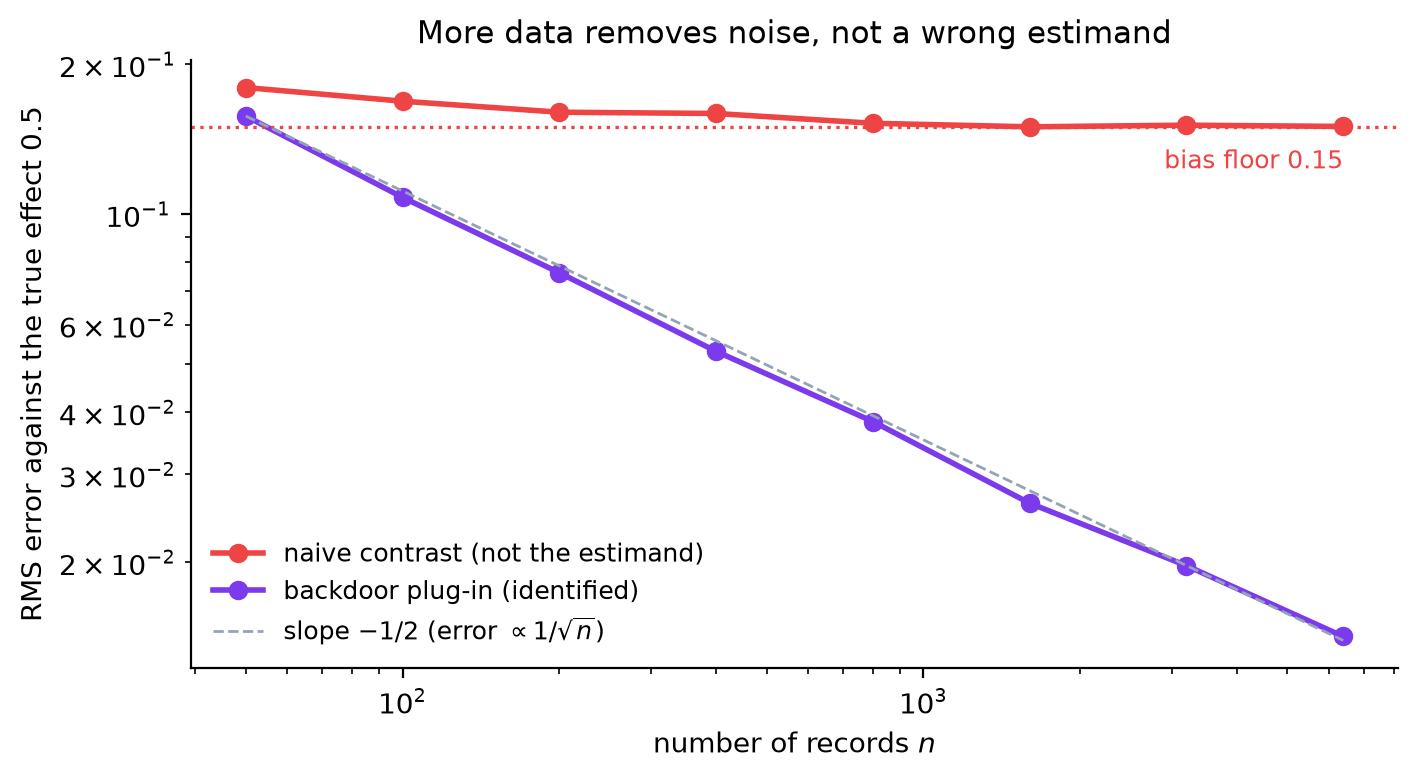

In [3]:
_show_mpl(_lessonfigs.error_vs_n())

*Root-mean-square error against the true effect $0.5$ in the worked-example model, 300 simulated studies per sample size. The backdoor plug-in estimator targets the identified estimand, and its error falls like $1/\sqrt{n}$. The naive contrast estimates a different quantity, $0.81 - 0.16 = 0.65$, and its error levels off at the bias $0.15$.*

## Compute it

Exact arithmetic with fractions: the two models of the first section give the same joint distribution and different interventional answers, and the mixture with weight $\lambda$ has effect $0.6\lambda$ with the joint unchanged.


In [4]:
from fractions import Fraction as F
from itertools import product

px1 = F(1, 2)                         # P(X = 1)
py1_x = {0: F(1, 5), 1: F(4, 5)}      # P(Y = 1 | X = x)
cells = list(product((0, 1), repeat=2))

def model_A():
    """X -> Y: X from P(x), then Y from P(y | x). Returns the joint and P(Y=1 | do(X=x))."""
    joint = {(x, y): (px1 if x else 1 - px1) * (py1_x[x] if y else 1 - py1_x[x]) for x, y in cells}
    return joint, {x: py1_x[x] for x in (0, 1)}

def model_B():
    """Hidden U -> X and U -> Y, no arrow X -> Y: U from P(y), X from P(x | y = U), Y = U."""
    jA, _ = model_A()
    pu1 = jA[(0, 1)] + jA[(1, 1)]
    joint = {c: F(0) for c in cells}
    for u in (0, 1):
        pu = pu1 if u else 1 - pu1
        for x in (0, 1):
            joint[(x, u)] += pu * jA[(x, u)] / (jA[(0, u)] + jA[(1, u)])
    return joint, {x: pu1 for x in (0, 1)}        # do(X = x) leaves U, hence Y, alone

jA, dA = model_A()
jB, dB = model_B()
print("cell (x,y)   model A   model B")
for c in cells:
    print(f"   {c}      {str(jA[c]):>5}     {str(jB[c]):>5}")
print("identical joints:", jA == jB)
print("P(Y=1 | do(X=x)), model A:", [str(dA[x]) for x in (0, 1)], " model B:", [str(dB[x]) for x in (0, 1)])

# a hidden coin picks model A with probability lam: same joint, effect 0.6 * lam
for lam in (F(0), F(1, 4), F(1, 2), F(1)):
    joint = {c: lam * jA[c] + (1 - lam) * jB[c] for c in cells}
    ace = lam * (dA[1] - dA[0]) + (1 - lam) * (dB[1] - dB[0])
    print(f"lam = {str(lam):>3}: joint unchanged {joint == jA}, effect = {float(ace):.2f}")

cell (x,y)   model A   model B
   (0, 0)        2/5       2/5
   (0, 1)       1/10      1/10
   (1, 0)       1/10      1/10
   (1, 1)        2/5       2/5
identical joints: True
P(Y=1 | do(X=x)), model A: ['1/5', '4/5']  model B: ['1/2', '1/2']
lam =   0: joint unchanged True, effect = 0.00
lam = 1/4: joint unchanged True, effect = 0.15
lam = 1/2: joint unchanged True, effect = 0.30
lam =   1: joint unchanged True, effect = 0.60


Estimation after identification. Simulate the worked-example model, compare the naive contrast with the backdoor plug-in estimate and its bootstrap interval, and cross-check the exact values with `qcai.science.causal`, which implements the same model. Then sample model B: the observed contrast settles at $0.6$ while the true effect is $0$.


In [5]:
import numpy as np
from qcai import science

# Worked-example model: Z -> X -> Y and Z -> Y, all observed (Markovian)
rng = np.random.default_rng(2024)
n = 20000
z = rng.random(n) < 0.4
x = rng.random(n) < np.where(z, 0.7, 0.2)
y = rng.random(n) < 0.1 + 0.5 * x + 0.3 * z

def naive(x, y):
    return y[x].mean() - y[~x].mean()

def backdoor(x, y, z):
    """Plug-in estimate of sum_z P(z) [P(Y=1 | X=1, z) - P(Y=1 | X=0, z)]."""
    return sum(np.mean(z == v) * (y[x & (z == v)].mean() - y[~x & (z == v)].mean()) for v in (False, True))

exact = science.causal(prevalence=0.4, low=0.2, high=0.7, base=0.1, effect=0.5, confound=0.3)
print("exact: do(1) =", round(exact["do1"], 4), " do(0) =", round(exact["do0"], 4),
      " effect =", round(exact["ate"], 4), " naive contrast =", round(exact["observed"], 4))
est = backdoor(x, y, z)
boot = []
for b in range(200):                      # nonparametric bootstrap of the plug-in estimator
    i = rng.integers(0, n, n)
    boot.append(backdoor(x[i], y[i], z[i]))
lo, hi = np.percentile(boot, [2.5, 97.5])
print(f"n = {n}: naive {naive(x, y):.3f}, backdoor {est:.3f}  (95% bootstrap interval {lo:.3f} to {hi:.3f})")

# Model B from the first section: the observed contrast converges to 0.6, its true effect is 0
for m in (100, 10_000, 1_000_000):
    u = rng.random(m) < 0.5
    xb = rng.random(m) < np.where(u, 0.8, 0.2)
    print(f"model B, n = {m:>9,}: observed contrast {naive(xb, u):.3f}   true effect 0   SE about {0.8 / np.sqrt(m):.4f}")

exact: do(1) = 0.72  do(0) = 0.22  effect = 0.5  naive contrast = 0.65
n = 20000: naive 0.654, backdoor 0.506  (95% bootstrap interval 0.490 to 0.521)
model B, n =       100: observed contrast 0.644   true effect 0   SE about 0.0800
model B, n =    10,000: observed contrast 0.584   true effect 0   SE about 0.0080
model B, n = 1,000,000: observed contrast 0.600   true effect 0   SE about 0.0008


:::{prf:remark} What the bootstrap interval does and does not cover
The bootstrap interval describes sampling variability of the plug-in estimator, the first term of [](#eq-l4-07-split). It says nothing about the second term. An interval computed for the naive contrast in model B would be narrow, centered near $0.6$, and would miss the true effect $0$.
:::

## Worked example

:::{admonition} Truncated factorization in a confounded model
:class: tip

In a Markovian model with graph $Z \to X \to Y$, $Z \to Y$ (all binary and observed), $P(Z{=}1) = 0.4$, $P(X{=}1 \mid Z{=}0) = 0.2$, $P(X{=}1 \mid Z{=}1) = 0.7$ and $P(Y{=}1 \mid X, Z) = 0.1 + 0.5X + 0.3Z$. Find $P(Y{=}1 \mid do(X{=}x))$ for $x = 0, 1$, the average effect, and the naive observed contrast.

1. Identification: the model is Markovian, so by the truncated factorization $P(y \mid do(x)) = \sum_z P(z)P(y \mid x, z)$, equation [](#eq-l4-07-trunc). Positivity holds because every $(x, z)$ cell has positive probability.
2. Treated: $P(Y{=}1 \mid do(X{=}1)) = P(Y{=}1 \mid 1, 0)P(Z{=}0) + P(Y{=}1 \mid 1, 1)P(Z{=}1) = 0.6 \cdot 0.6 + 0.9 \cdot 0.4 = 0.72$.
3. Untreated: $P(Y{=}1 \mid do(X{=}0)) = 0.1 \cdot 0.6 + 0.4 \cdot 0.4 = 0.22$, so the average effect is $0.72 - 0.22 = 0.5$, the coefficient of $X$.
4. Naive contrast: $P(X{=}1) = 0.6 \cdot 0.2 + 0.4 \cdot 0.7 = 0.4$, so $P(Z{=}1 \mid X{=}1) = 0.28/0.4 = 0.7$ and $P(Y{=}1 \mid X{=}1) = 0.6 \cdot 0.3 + 0.9 \cdot 0.7 = 0.81$; similarly $P(Z{=}1 \mid X{=}0) = 0.12/0.6 = 0.2$ and $P(Y{=}1 \mid X{=}0) = 0.1 \cdot 0.8 + 0.4 \cdot 0.2 = 0.16$.
5. Comparison: the naive contrast $0.81 - 0.16 = 0.65$ overstates the effect by $0.15$ because treated units more often have $Z = 1$, which raises $Y$ on its own.

**Result.** $P(Y{=}1 \mid do(X{=}1)) = 0.72$, $P(Y{=}1 \mid do(X{=}0)) = 0.22$, average effect $0.5$; the naive contrast $0.65$ answers a different question.
:::

## Exercises

**1. (Core)** Let $U$ be a fair binary variable. Model A' has $X = U$ and $Y = X$; model B' has $X = U$ and $Y = U$. Calculate $P(Y{=}1 \mid do(X{=}0))$ in each. Can an unlimited observational sample choose between their answers?

:::{dropdown} Solution
Model A' gives $0$, because $Y$ copies the set value of $X$. Model B' gives $1/2$, because $Y = U$ and $U$ stays fair when $X$ is set. Both models produce only the pairs $(0,0)$ and $(1,1)$, each with probability $1/2$, so their observational distributions are identical and no observational sample, however large, can separate them. (This toy also violates positivity, since $X = 0, Y = 1$ never occurs; the models of the first section show that non-identification does not need that.)
:::

**2. (Core)** In a Markovian chain $X \to M \to Y$ with $P(M{=}1 \mid X{=}1) = 0.7$, $P(Y{=}1 \mid M{=}1) = 0.9$ and $P(Y{=}1 \mid M{=}0) = 0.2$, use the truncated factorization to find $P(Y{=}1 \mid do(X{=}1))$. Why does it equal $P(Y{=}1 \mid X{=}1)$ here?

:::{dropdown} Solution
Truncation deletes $P(x)$: $P(m, y \mid do(x)) = P(m \mid x)P(y \mid m)$. Summing over $m$, $P(Y{=}1 \mid do(X{=}1)) = 0.7 \cdot 0.9 + 0.3 \cdot 0.2 = 0.63 + 0.06 = 0.69$. Since $X$ has no parents, the deleted factor carries no confounding, and $P(y \mid x) = \sum_m P(m \mid x)P(y \mid m)$ is the same sum: $(Y \perp\!\!\!\perp X)_{G_{\underline{X}}}$ holds, so Rule 2 applies directly.
:::

**3. (Stretch)** For the joint distribution of the first section, show that without any assumption about hidden variables $P(Y{=}1 \mid do(X{=}1))$ can be any value in $[0.4, 0.9]$ and nothing outside it, and deduce the interval for the effect $P(Y{=}1 \mid do(X{=}1)) - P(Y{=}1 \mid do(X{=}0))$.

:::{dropdown} Solution
Write $Y_1$ for the outcome a unit would have under $do(X{=}1)$, so $P(Y{=}1 \mid do(X{=}1)) = P(Y_1 = 1)$. Split by the observed $X$: $P(Y_1{=}1) = P(Y_1{=}1, X{=}1) + P(Y_1{=}1, X{=}0)$. For units with $X = 1$ the intervention changes nothing, so $Y_1 = Y$ and the first term is $P(Y{=}1, X{=}1) = 0.4$. The second term concerns units never seen treated; the data constrain it only to $[0, P(X{=}0)] = [0, 0.5]$, and any value in that range is achieved by assigning $Y_1$ to those units accordingly. Hence $[0.4, 0.9]$. In the same way $P(Y{=}1 \mid do(X{=}0)) \in [P(X{=}0, Y{=}1), P(X{=}0, Y{=}1) + P(X{=}1)] = [0.1, 0.6]$. The effect lies in $[0.4 - 0.6, 0.9 - 0.1] = [-0.2, 0.8]$, an interval of width $1$, which always contains $0$ for binary $Y$ without further assumptions.
:::

**4. (Stretch)** Let a hidden coin $S$ with $P(S{=}1) = \lambda$ choose the mechanisms: if $S = 1$ the unit follows model A, if $S = 0$ it follows model B. Show that the joint $P(x, y)$ does not depend on $\lambda$ and that the effect is $0.6\lambda$. Which graph is this model compatible with?

:::{dropdown} Solution
Conditioning on $S$, $P(x, y) = \lambda P_A(x, y) + (1 - \lambda)P_B(x, y) = P(x, y)$, since $P_A = P_B$. Under $do(X{=}x)$ the coin is untouched, so $P(Y{=}1 \mid do(x)) = \lambda P_A(Y{=}1 \mid do(x)) + (1 - \lambda)P_B(Y{=}1 \mid do(x))$, which gives $\lambda(0.8 - 0.2) + (1 - \lambda)(0.5 - 0.5) = 0.6\lambda$. The hidden pair $(S, U)$ points into both $X$ and $Y$, and $X$ points into $Y$, so the model fits the bow graph. Every effect in $[0, 0.6]$ is therefore compatible with the same data and graph.
:::

**5. (Challenge)** Frontdoor graph: $X \to M \to Y$ with a hidden $U$ pointing into $X$ and $Y$ and no other arrows. Using only the three rules (state the graph and the separation for each use), derive $P(y \mid do(x)) = \sum_m P(m \mid x)\sum_{x'} P(y \mid m, x')P(x')$.

:::{dropdown} Solution
(a) $P(m \mid do(x)) = P(m \mid x)$ by Rule 2: in $G_{\underline{X}}$ (delete $X \to M$) the only path from $X$ to $M$ is $X \leftarrow U \to Y \leftarrow M$, blocked at the collider $Y$. (b) $P(y \mid do(m)) = \sum_{x'} P(y \mid do(m), x')P(x' \mid do(m))$. Rule 3 gives $P(x' \mid do(m)) = P(x')$: in $G_{\overline{M}}$ (delete $X \to M$) the path $X \leftarrow U \to Y \leftarrow M$ is blocked at $Y$. Rule 2 gives $P(y \mid do(m), x') = P(y \mid m, x')$: in $G_{\underline{M}}$ (delete $M \to Y$) the only path $M \leftarrow X \leftarrow U \to Y$ is blocked by conditioning on the noncollider $X$. (c) $P(y \mid do(x)) = \sum_m P(y \mid do(x), m)P(m \mid do(x))$. Rule 2 gives $P(y \mid do(x), m) = P(y \mid do(x), do(m))$: in $G_{\overline{X}\underline{M}}$ (delete $U \to X$ and $M \to Y$) $M$ is connected only to $X$, and $X$ has no path to $Y$. Rule 3 gives $P(y \mid do(x), do(m)) = P(y \mid do(m))$: here $W$ is empty, so $Z(W) = \{X\}$ and the graph to check is $G_{\overline{M}\,\overline{X}}$ (delete $X \to M$ and $U \to X$), where $X$ has no edges at all. Substituting (a) and (b) into (c) gives the frontdoor formula.
:::

## Check your understanding

**1. Two causal models produce the same exact observational distribution but different values of $P(y \mid do(x))$. What can settle which value is right?**

- **A.** A more flexible regression model
- **B.** A narrower confidence interval
- **C.** A larger observational sample of the same variables
- **D.** Additional justified assumptions or informative interventions

:::{dropdown} Show the answer
**D. Additional justified assumptions or informative interventions**

Both models fit the exact distribution, so more data, narrower intervals and better-fitting regressions all leave the disagreement in place. Only information that the models treat differently, such as experimental data or a justified restriction that rules one out, can decide.
:::

**2. In a Markovian model with graph $Z \to X \to Y$ and $Z \to Y$, what is $P(z, y \mid do(x))$?**

- **A.** $P(z)\,P(x \mid z)\,P(y \mid x, z)$
- **B.** $P(z)\,P(y \mid x, z)$
- **C.** $P(y \mid x)\,P(z)$
- **D.** $P(z \mid x)\,P(y \mid x, z)$

:::{dropdown} Show the answer
**B. $P(z)\,P(y \mid x, z)$**

The truncated factorization deletes the factor $P(x \mid z)$ of the intervened variable and keeps the other factors with $x$ substituted. Using $P(z \mid x)$ would reintroduce the confounding by $Z$.
:::

**3. Which d-separation licenses rewriting $P(y \mid do(x), z)$ as $P(y \mid x, z)$?**

- **A.** $(Y \perp\!\!\!\perp Z)$ in the original graph
- **B.** Any correlation between $X$ and $Y$ given $Z$
- **C.** $(Y \perp\!\!\!\perp X \mid Z)$ in $G_{\underline{X}}$, the graph without arrows out of $X$
- **D.** $(Y \perp\!\!\!\perp X \mid Z)$ in $G_{\overline{X}}$, the graph without arrows into $X$

:::{dropdown} Show the answer
**C. $(Y \perp\!\!\!\perp X \mid Z)$ in $G_{\underline{X}}$, the graph without arrows out of $X$**

This is Rule 2, exchanging an action for an observation. Removing the arrows out of $X$ leaves only the backdoor paths; if $Z$ blocks all of them, seeing $X = x$ and setting $X = x$ give the same conditional distribution of $Y$.
:::

**4. In the graph $Z \to X \to Y$, $Z \to Y$ with all variables observed, which set satisfies the backdoor criterion for the effect of $X$ on $Y$?** *(Review of [L4-04](#lesson-l4-04))*

- **A.** The empty set
- **B.** $\{Z\}$
- **C.** No set does
- **D.** $\{Y\}$

:::{dropdown} Show the answer
**B. $\{Z\}$**

The backdoor path $X \leftarrow Z \to Y$ is open without adjustment; conditioning on $Z$ blocks it, and $Z$ is not a descendant of $X$. So $\{Z\}$ is valid and gives $\sum_z P(y \mid x, z)P(z)$.
:::

## Common misconceptions

- **"With enough data the causal effect will reveal itself."** Data converge to the observational distribution. If two models share that distribution and disagree about the effect, as models A and B do, the limit of infinite data still leaves the effect undetermined. Sample size controls the estimation error, not the identification gap.
- **"A model that predicts the data well gives the right causal answers."** Models A and B predict every observational frequency perfectly. Predictive fit tests the observational distribution only; causal answers depend on the mechanism assumptions that fit cannot check.
- **"Do-calculus lets you drop the do operator once you condition on enough variables."** Each rule applies only when a specific d-separation holds in a specific mutilated graph. Conditioning on a collider or a descendant of $X$ can open paths and make the rewrite false.

:::{caution} Scope and limits
This lesson treats nonparametric identification: no functional form is assumed beyond the graph. Parametric assumptions (linearity, an instrumental variable with a monotone effect, a known noise distribution) can identify more, and they are assumptions that need their own justification. The truncated factorization needs independent noises and positivity; with near-violations of positivity an identified estimand can still be estimated very poorly. The do-calculus is known to be complete for identifying $P(y \mid do(x))$ from the observational distribution in graphs with hidden variables, a result due to Shpitser and Pearl (2006) and to Huang and Valtorta (2006) [@huangvaltorta2006]. The simulations are illustrations, not empirical evidence about any treatment.
:::

:::{seealso} Where this leads
Identification of an effect from a known graph is the first half of the story. [L4-08](#lesson-l4-08) asks the mirror question, whether the graph itself is identified from data, and finds the same pattern: observationally equivalent graphs that only assumptions or interventions can separate. [L4-09](#lesson-l4-09) climbs to counterfactuals, where even interventional data can leave answers unidentified, and [L4-10](#lesson-l4-10) applies identification to transport between populations. The quantum causal models of Level 6 face the same split between what a causal structure implies and what statistics can reveal.
:::

:::{dropdown} For instructors

**Why this lesson.** Students often meet causal inference as a list of estimators and adjustment recipes. Putting identification first, with a concrete pair of models that no data can separate, makes the role of assumptions unavoidable and gives the do-calculus a clear purpose [@pearlcausality; @hernan].

**Teaching notes.**

- Before showing model B, ask students to propose any model that reproduces the table $0.4, 0.1, 0.1, 0.4$ with zero effect. Most find a confounder story within minutes; the formal definition then reads as a summary of what they did.
- Use the interactive to show that the gray no-assumption bounds always contain both the mixture's answers and $0$; ask what assumption would shrink the interval to a point.
- In the do-calculus derivation, make students name the target, the action and $W$ before choosing the mutilated graph. Most errors come from checking the separation in the original graph.
- Pair the error decomposition [](#eq-l4-07-split) with the figure: confidence intervals address only the first term.

**Assessment.** The challenge exercise (frontdoor by the three rules) tests whether students can apply each rule with the correct graph. The stretch exercise on bounds tests whether they can reason about what data leave unconstrained. The check questions cover the core definitions.

**Going further.** Show that the bow graph's effect becomes identified if an instrument $I \to X$ with a linear outcome model is assumed, and discuss which part of that is an assumption. For a full treatment of identification algorithms with hidden variables, see Pearl's *Causality*, chapter 3 [@pearlcausality], and Bareinboim's roadmap [@bareinboim].

:::

## References

This lesson draws on [@pearlcausality; @pearl; @frontdoor; @peters; @hernan; @bareinboim; @huangvaltorta2006].

**Further reading.**

- [@pearlcausality]: Chapter 3 defines identifiability, proves the truncated factorization and presents the do-calculus.
- [@hernan]: Part I separates identification conditions (exchangeability, positivity, consistency) from estimation.
- [@peters]: Chapter 6 treats interventions and adjustment in multivariate SCMs.

**Next:** [L4-08 · Causal discovery and its limits](#lesson-l4-08)
